# Simulation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display
import matplotlib 
matplotlib.rc('font', family='serif')
matplotlib.rc('font', serif='STIXGeneral')
from cmcrameri import cm  #cmap=cm.lipari 
matplotlib.rcParams['animation.embed_limit'] = 50  # MB
import matplotlib as mpl





Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Global variables

In [2]:
dimension = 256*2 #size of matrix
background_num = 5 #No. of background objects # updated from original
frames_num = 50    # number of animation frames 


## Object & background 

In [3]:
# Fixed background
random_num = np.random.default_rng(2)
bg_positions = random_num.integers(0.2*dimension,0.8*dimension, size=(background_num, 2))

In [4]:

# Object matrix
def make_object(t):
    '''creates a vertical and horizontal linear moving object relative to a fixed background'''

    Obj = np.zeros((dimension, dimension))

    # Static background dots
    for y, x in bg_positions:
        Obj[y, x] = 1

    centre_x = dimension // 2
    centre_y = dimension // 2
    amp_x = 60
    amp_y = 60

    # Object 1 (horizontal linear)
    x1 = int(centre_x + amp_x * np.sin(t))
    y1 = int(centre_y+20) # updates from original

    # Object 2 (vertical linear)
    x2 = int(centre_x-10) #updated from original
    y2 = int(centre_y + amp_y * np.sin(t))

    Obj[y1, x1] = 1
    Obj[y2, x2] = 1

    Obj = gaussian_filter(Obj, sigma=2)

    return Obj

### Animation

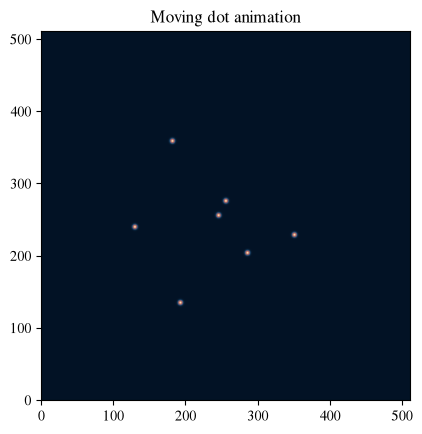

In [5]:
# animation
fig, ax = plt.subplots()
img = ax.imshow(make_object(0), origin='lower',cmap=cm.lipari )
ax.set_title("Moving dot animation")
bg_frame=[]

def animation_make_object(frame):
    '''inputs value for t to make each image frame'''
    t = 2 * np.pi * frame / frames_num
    img.set_data(make_object(t))
    bg_frame.append(make_object(t))
    return [img]

anim = FuncAnimation(fig, animation_make_object, frames=frames_num, interval=80)
HTML(anim.to_jshtml())

In [6]:
# Save object video
'''gif_writer = PillowWriter(fps=15)
anim.save("moving_two_object_linear2.0.gif", writer=gif_writer)'''
'''from matplotlib.animation import FFMpegWriter

video_writer = FFMpegWriter(fps=15)
anim.save("moving_two_object_linear2.0.mp4", writer=video_writer)'''

'from matplotlib.animation import FFMpegWriter\n\nvideo_writer = FFMpegWriter(fps=15)\nanim.save("moving_two_object_linear2.0.mp4", writer=video_writer)'

## Random Speckle Pattern

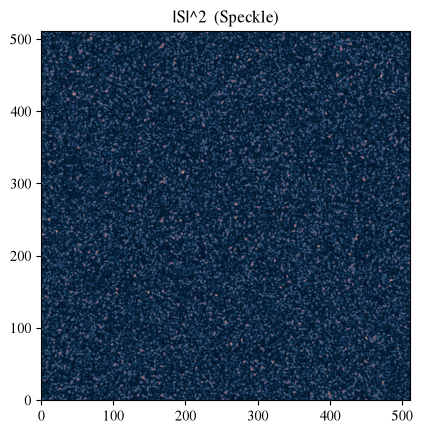

In [7]:
# Coordinate grid, 0 centred 
Y, X = np.indices((dimension, dimension))
X = X - dimension//2
Y = Y - dimension//2

#gaussian envelope
sigma_env = 80 #standard deviation # updated from original  
gaussian_env = np.exp(-(X**2 + Y**2) / (2 * sigma_env**2))

# Random complex matrix
rand_complex = (
    np.random.uniform(-1, 1, (dimension, dimension)) + 1j * np.random.uniform(-1, 1, (dimension, dimension))
)

# field at barrier
field = rand_complex * gaussian_env


# speckle pattern - random
speckle_rand = np.fft.fftshift(np.fft.fft2(field)) # fast fourier transform, shift to centre
intensity_rand = np.abs(speckle_rand)**2

plt.imshow(intensity_rand, origin='lower',cmap=cm.lipari )
plt.title("|S|^2  (Speckle)")
plt.show()

## Tracking Object

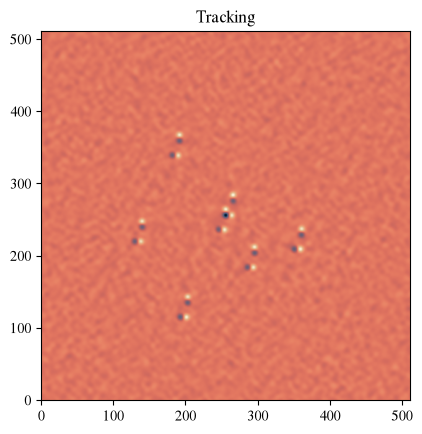

In [8]:

prev_image_clean = None
fft_speckle = np.fft.fft2(intensity_rand)
frame_list=[]

def track_object(frame):
    '''convolve object and speckle, track object using correlation I(t) ⋆ I(t-1) - I(t) ⋆ I(t)'''
    
    global prev_image_clean
    global fft_speckle
    t = 2 * np.pi * frame / frames_num
    Obj = make_object(t)

    # Convolution of speckle and object
    image = np.fft.ifft2(np.fft.fft2(Obj) * fft_speckle)
    image = np.real(image)

    # Remove background
    image_clean = image - np.mean(image)

    # for first frame
    if prev_image_clean is None:
        prev_image_clean = image_clean
        img.set_data(image_clean)
        img.set_clim(vmin=image_clean.min(), vmax=image_clean.max())
        return [img]

    # correlation - I(t) ⋆ I(t-1)
    correlation_shift = np.fft.ifft2(np.fft.fft2(image_clean) * np.conj(np.fft.fft2(prev_image_clean)))

    # correlation - I(t) ⋆ I(t)
    correlation_auto = np.fft.ifft2(np.fft.fft2(image_clean) * np.conj(np.fft.fft2(image_clean)))

    result = np.real(correlation_shift - correlation_auto)
    result = np.fft.fftshift(result)
    result=np.real(result)
    
    result -= np.mean(result)

    img.set_data(result)
    img.set_clim(vmin=result.min(), vmax=result.max())
    
    prev_image_clean = image_clean
    frame_list.append(result)

    return [img]

fig, ax = plt.subplots()
img = ax.imshow(np.zeros_like(intensity_rand), cmap=cm.lipari, animated=True,origin='lower',)

ax.set_title("Tracking")

#create animation
animation_tracking = FuncAnimation(fig, track_object, frames=frames_num, interval=80)

HTML(animation_tracking.to_jshtml())


# Background Shift Tracking

## Shifts For All Frames

In [9]:
y_shifts_1 = []
x_shifts_1 = []

y_shifts_2 = []
x_shifts_2 = []

previous_1 = None
previous_2 = None

for n in range(len(frame_list)-1):

    reference_background = np.asarray(bg_frame[0], dtype=float)
    comparison_frame = np.asarray(frame_list[n+1], dtype=float)

    reference_norm = np.sqrt(np.sum(reference_background**2))
    comparison_norm = np.sqrt(np.sum(comparison_frame**2))

    if reference_norm == 0 or comparison_norm == 0:
        continue

    correlation = np.fft.ifft2(
        np.fft.fft2(comparison_frame) *
        np.conj(np.fft.fft2(reference_background))
    )

    correlation = np.fft.fftshift(np.real(correlation))
    correlation /= reference_norm * comparison_norm

    smooth = gaussian_filter(correlation, sigma=2)
    candidates = np.argsort(smooth.ravel())[::-1]

    peaks = []
    min_separation = 20

    for index in candidates:
        y, x = np.unravel_index(index, correlation.shape)

        if all(
            np.sqrt((y-py)**2 + (x-px)**2) >= min_separation
            for py, px in peaks
        ):
            peaks.append((y, x))

        if len(peaks) == 2:
            break

    if len(peaks) != 2:
        continue

    centre_y = correlation.shape[0] // 2
    centre_x = correlation.shape[1] // 2

    # Convert peaks to (x, y) shifts
    shifts = [
        (x-centre_x, y-centre_y)
        for y, x in peaks
    ]

        # --------------------------------------------------
    # Categorise peaks based on previous positions
    # --------------------------------------------------

    if previous_1 is None:

        # Initialise the two peak identities
        shift_1 = shifts[0]
        shift_2 = shifts[1]

    else:

        # Calculate distances from both current peaks
        # to both previously tracked peaks

        distance_1_to_1 = np.linalg.norm(
            np.array(shifts[0]) - previous_1
        )

        distance_1_to_2 = np.linalg.norm(
            np.array(shifts[1]) - previous_1
        )

        distance_2_to_1 = np.linalg.norm(
            np.array(shifts[0]) - previous_2
        )

        distance_2_to_2 = np.linalg.norm(
            np.array(shifts[1]) - previous_2
        )

        # Assignment A: keep the original peak order
        cost_A = distance_1_to_1 + distance_2_to_2

        # Assignment B: swap the peak order
        cost_B = distance_1_to_2 + distance_2_to_1

        # Choose whichever assignment gives the
        # smallest total displacement
        if cost_A <= cost_B:

            shift_1 = shifts[0]
            shift_2 = shifts[1]

        else:

            shift_1 = shifts[1]
            shift_2 = shifts[0]


    # Save the associated shifts
    x_shifts_1.append(shift_1[0])
    y_shifts_1.append(shift_1[1])

    x_shifts_2.append(shift_2[0])
    y_shifts_2.append(shift_2[1])

    # Update previous positions
    previous_1 = np.array(shift_1)
    previous_2 = np.array(shift_2)

## Plotting

In [13]:
%pip install imageio-ffmpeg
import matplotlib as mpl
import imageio_ffmpeg

mpl.rcParams["animation.ffmpeg_path"] = (
    imageio_ffmpeg.get_ffmpeg_exe()
)

print(mpl.rcParams["animation.ffmpeg_path"])

Note: you may need to restart the kernel to use updated packages.
c:\Users\Student\AppData\Local\Programs\Python\Python314\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
# Estimated correlation shifts

# Object 1 calculated path
plot_x_1 = -np.asarray(y_shifts_1, dtype=float)
plot_y_1 = -np.asarray(x_shifts_1, dtype=float)

# Object 2 calculated path
plot_x_2 = -np.asarray(y_shifts_2, dtype=float)
plot_y_2 = -np.asarray(x_shifts_2, dtype=float)

num_shift_points = min(
    len(plot_x_1),
    len(plot_y_1),
    len(plot_x_2),
    len(plot_y_2)
)

# Reconstruct the fixed background like make_object()
background = np.zeros((dimension, dimension))

for y, x in bg_positions:
    background[y, x] = 1

background = gaussian_filter(background, sigma=2)


# Find the two moving objects in make_object(t)
def find_moving_objects(t, previous_positions=None):
    """
    Get the two moving-object positions from make_object(t).
    The fixed background is subtracted first.
    If previous positions are supplied, assign each new
    position to the nearest previous position.
    """
    obj = make_object(t)
    moving = np.clip(obj - background, 0, None)

    threshold = moving.max() * 0.35
    candidates = np.argwhere(moving >= threshold)

    if len(candidates) < 2:
        flat_indices = np.argpartition(moving.ravel(), -2)[-2:]
        candidates = np.array([
            np.unravel_index(p, moving.shape) for p in flat_indices
        ])

    if previous_positions is not None:
        selected = []
        remaining = list(candidates)

        for px, py in previous_positions:
            if not remaining:
                break

            distances = [
                (x - px)**2 + (y - py)**2
                for y, x in remaining
            ]

            index = int(np.argmin(distances))
            y, x = remaining.pop(index)
            selected.append((x, y))

        if len(selected) == 2:
            return selected

    points = [(int(x), int(y)) for y, x in candidates]

    if len(points) > 2:
        p1 = points[0]
        p2 = max(
            points[1:],
            key=lambda p: (p[0] - p1[0])**2 + (p[1] - p1[1])**2
        )
        return [p1, p2]

    return points[:2]


# Calculate the positions for every frame
object_positions = []
previous_positions = None

for frame in range(frames_num):
    t = 2 * np.pi * frame / frames_num

    positions = find_moving_objects(
        t,
        previous_positions=previous_positions
    )

    object_positions.append(positions)
    previous_positions = positions


# Create the three plots
fig, (ax_image, ax_actual, ax_shifts) = plt.subplots(
    1, 3, figsize=(18, 6)
)


# Left: original image
im = ax_image.imshow(
    make_object(0),
    origin="lower",
    cmap=cm.lipari,
    interpolation="nearest"
)

ax_image.set_title("Animation, +20 y_1, -10 x_2")
ax_image.set_xlabel("x (pixels)")
ax_image.set_ylabel("y (pixels)")


# Centre: positions extracted from make_object()
dot1, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 1"
)

dot2, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 2"
)

path1, = ax_actual.plot([], [], "-", alpha=0.7)
path2, = ax_actual.plot([], [], "-", alpha=0.7)

ax_actual.set_xlim(0, dimension)
ax_actual.set_ylim(0, dimension)
ax_actual.set_aspect("equal", adjustable="box")
ax_actual.set_title("Actual Object Trajectories")
ax_actual.set_xlabel("x (pixels)")
ax_actual.set_ylabel("y (pixels)")
ax_actual.legend()
ax_actual.grid(alpha=0.3)


# Right: correlation-derived shifts
# Colour represents time using the original cm.lipari map

vmin = 0
vmax = max(num_shift_points - 1, 1)

shift_scatter = ax_shifts.scatter(
    [],
    [],
    s=25,
    c=[],
    cmap=cm.lipari,
    vmin=vmin,
    vmax=vmax
)

ax_shifts.axhline(0, color="gray", linewidth=0.8)
ax_shifts.axvline(0, color="gray", linewidth=0.8)

ax_shifts.set_xlim(-100, 100)
ax_shifts.set_ylim(-100, 100)
ax_shifts.set_aspect("equal", adjustable="box")
ax_shifts.set_title("Calculated Path Split")
ax_shifts.set_xlabel("−dx (pixels)")
ax_shifts.set_ylabel("−dy (pixels)")
ax_shifts.grid(alpha=0.3)

fig.colorbar(
    shift_scatter,
    ax=ax_shifts,
    fraction=0.046,
    pad=0.04,
    label="Time (Frames)"
)

fig.tight_layout()


# Animation update
def update_triple(frame):

    t = 2 * np.pi * frame / frames_num

    # Left plot: original image from make_object()
    im.set_data(make_object(t))

    # Centre plot: positions extracted from make_object()
    positions = object_positions[frame]

    if len(positions) >= 2:
        x1, y1 = positions[0]
        x2, y2 = positions[1]

        dot1.set_data([x1], [y1])
        dot2.set_data([x2], [y2])

    # Show each object's trajectory up to current frame
    path1.set_data(
        [p[0][0] for p in object_positions[:frame + 1]],
        [p[0][1] for p in object_positions[:frame + 1]]
    )

    path2.set_data(
        [p[1][0] for p in object_positions[:frame + 1]],
        [p[1][1] for p in object_positions[:frame + 1]]
    )


    # Right plot: progressively reveal both objects

    visible_count = min(
        int((frame + 1) * num_shift_points / frames_num),
        num_shift_points
    )

    # Coordinates for each object
    offsets_1 = np.column_stack((
        plot_x_1[:visible_count],
        plot_y_1[:visible_count]
    ))

    offsets_2 = np.column_stack((
        plot_x_2[:visible_count],
        plot_y_2[:visible_count]
    ))

    # Interleave objects frame-by-frame
    all_offsets = np.stack(
        (offsets_1, offsets_2),
        axis=1
    ).reshape(-1, 2)

    # Time colour for each point
    all_colours = np.repeat(
        np.arange(visible_count),
        2
    )

    # Update scatter coordinates and colours
    shift_scatter.set_offsets(all_offsets)
    shift_scatter.set_array(all_colours)

    return (
        im,
        dot1,
        dot2,
        path1,
        path2,
        shift_scatter
    )


# Run the animation
triple_anim = FuncAnimation(
    fig,
    update_triple,
    frames=frames_num,
    interval=80,
    blit=False
)


# Save the animation as a video
from matplotlib.animation import FFMpegWriter

writer = FFMpegWriter(fps=12, bitrate=1800)
triple_anim.save(
     "cross_tracking_two_linear_offset_split.mp4",
     writer=writer,
     dpi=150
 )

plt.close(fig)

display(HTML(triple_anim.to_jshtml()))

In [15]:
# Estimated correlation shifts

# Object 1 calculated path
plot_x_1 = -np.asarray(y_shifts_1, dtype=float)
plot_y_1 = -np.asarray(x_shifts_1, dtype=float)

# Object 2 calculated path
plot_x_2 = -np.asarray(y_shifts_2, dtype=float)
plot_y_2 = -np.asarray(x_shifts_2, dtype=float)

num_shift_points = min(
    len(plot_x_1),
    len(plot_y_1),
    len(plot_x_2),
    len(plot_y_2)
)


# Reconstruct the fixed background like make_object()
background = np.zeros((dimension, dimension))

for y, x in bg_positions:
    background[y, x] = 1

background = gaussian_filter(background, sigma=2)


# Find the two moving objects in make_object(t)
def find_moving_objects(t, previous_positions=None):

    obj = make_object(t)
    moving = np.clip(obj - background, 0, None)

    threshold = moving.max() * 0.35
    candidates = np.argwhere(moving >= threshold)

    if len(candidates) < 2:
        flat_indices = np.argpartition(moving.ravel(), -2)[-2:]

        candidates = np.array([
            np.unravel_index(p, moving.shape)
            for p in flat_indices
        ])

    if previous_positions is not None:

        selected = []
        remaining = list(candidates)

        for px, py in previous_positions:

            if not remaining:
                break

            distances = [
                (x - px)**2 + (y - py)**2
                for y, x in remaining
            ]

            index = int(np.argmin(distances))
            y, x = remaining.pop(index)

            selected.append((x, y))

        if len(selected) == 2:
            return selected

    points = [(int(x), int(y)) for y, x in candidates]

    if len(points) > 2:

        p1 = points[0]

        p2 = max(
            points[1:],
            key=lambda p: (p[0] - p1[0])**2
                        + (p[1] - p1[1])**2
        )

        return [p1, p2]

    return points[:2]


# Calculate positions for every frame
object_positions = []
previous_positions = None

for frame in range(frames_num):

    t = 2 * np.pi * frame / frames_num

    positions = find_moving_objects(
        t,
        previous_positions=previous_positions
    )

    object_positions.append(positions)
    previous_positions = positions


# --------------------------------------------------
# Create three plots
# --------------------------------------------------

fig, (ax_actual, ax_horizontal, ax_vertical) = plt.subplots(
    1, 3, figsize=(18, 6)
)


# --------------------------------------------------
# Left: Actual trajectories
# --------------------------------------------------

dot1, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 1"
)

dot2, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 2"
)

actual_path1, = ax_actual.plot(
    [], [], "-", alpha=0.7
)

actual_path2, = ax_actual.plot(
    [], [], "-", alpha=0.7
)

ax_actual.set_xlim(0, dimension)
ax_actual.set_ylim(0, dimension)
ax_actual.set_aspect("equal", adjustable="box")

ax_actual.set_title("Actual Object Trajectories")
ax_actual.set_xlabel("x (pixels)")
ax_actual.set_ylabel("y (pixels)")

ax_actual.legend()
ax_actual.grid(alpha=0.3)


# --------------------------------------------------
# Middle: Calculated horizontal trajectory
# --------------------------------------------------

vmin = 0
vmax = max(num_shift_points - 1, 1)

scatter_horizontal = ax_horizontal.scatter(
    [],
    [],
    s=25,
    c=[],
    cmap=cm.lipari,
    vmin=vmin,
    vmax=vmax
)

ax_horizontal.axhline(0, color="gray", linewidth=0.8)
ax_horizontal.axvline(0, color="gray", linewidth=0.8)

ax_horizontal.set_xlim(-100, 100)
ax_horizontal.set_ylim(-100, 100)

ax_horizontal.set_aspect("equal", adjustable="box")

ax_horizontal.set_title("Calculated Horizontal Trajectory")
ax_horizontal.set_xlabel("−dy (pixels)")
ax_horizontal.set_ylabel("−dx (pixels)")

ax_horizontal.grid(alpha=0.3)

fig.colorbar(
    scatter_horizontal,
    ax=ax_horizontal,
    fraction=0.046,
    pad=0.04,
    label="Time (Frames)"
)


# --------------------------------------------------
# Right: Calculated vertical trajectory
# --------------------------------------------------

scatter_vertical = ax_vertical.scatter(
    [],
    [],
    s=25,
    c=[],
    cmap=cm.lipari,
    vmin=vmin,
    vmax=vmax
)

ax_vertical.axhline(0, color="gray", linewidth=0.8)
ax_vertical.axvline(0, color="gray", linewidth=0.8)

ax_vertical.set_xlim(-100, 100)
ax_vertical.set_ylim(-100, 100)

ax_vertical.set_aspect("equal", adjustable="box")

ax_vertical.set_title("Calculated Vertical Trajectory")
ax_vertical.set_xlabel("−dy (pixels)")
ax_vertical.set_ylabel("−dx (pixels)")

ax_vertical.grid(alpha=0.3)

fig.colorbar(
    scatter_vertical,
    ax=ax_vertical,
    fraction=0.046,
    pad=0.04,
    label="Time (Frames)"
)

fig.tight_layout()


# --------------------------------------------------
# Animation update
# --------------------------------------------------

def update_triple(frame):

    # Actual object positions
    positions = object_positions[frame]

    if len(positions) >= 2:

        x1, y1 = positions[0]
        x2, y2 = positions[1]

        dot1.set_data([x1], [y1])
        dot2.set_data([x2], [y2])


    # Actual trajectories up to current frame
    actual_path1.set_data(
        [p[0][0] for p in object_positions[:frame + 1]],
        [p[0][1] for p in object_positions[:frame + 1]]
    )

    actual_path2.set_data(
        [p[1][0] for p in object_positions[:frame + 1]],
        [p[1][1] for p in object_positions[:frame + 1]]
    )


    # Number of calculated shift points to reveal
    visible_count = min(
        int((frame + 1) * num_shift_points / frames_num),
        num_shift_points
    )


    # Horizontal object
    offsets_1 = np.column_stack((
        plot_x_1[:visible_count],
        plot_y_1[:visible_count]
    ))

    colours_1 = np.arange(visible_count)

    scatter_horizontal.set_offsets(offsets_1)
    scatter_horizontal.set_array(colours_1)


    # Vertical object
    offsets_2 = np.column_stack((
        plot_x_2[:visible_count],
        plot_y_2[:visible_count]
    ))

    colours_2 = np.arange(visible_count)

    scatter_vertical.set_offsets(offsets_2)
    scatter_vertical.set_array(colours_2)


    return (
        dot1,
        dot2,
        actual_path1,
        actual_path2,
        scatter_horizontal,
        scatter_vertical
    )


# --------------------------------------------------
# Run animation
# --------------------------------------------------

triple_anim = FuncAnimation(
    fig,
    update_triple,
    frames=frames_num,
    interval=80,
    blit=False
)
# Save the animation as a video
from matplotlib.animation import FFMpegWriter

writer = FFMpegWriter(fps=12, bitrate=1800)
triple_anim.save(
     "cross_tracking_two_linear_offset_split_VH.mp4",
     writer=writer,
     dpi=150
 )
plt.close(fig)

display(HTML(triple_anim.to_jshtml()))